Loading and tokenizing the text, the sentences are seperated into their respective languages, punctuations are broken down into tokens and EOS and SOS tokens are added

In [1]:
import re

with open("data/fra.txt", "r", encoding="utf-8") as f:
    text = f.read()

text = text.split("\n")
english = []
french = []

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())


for lines in text:
    line = []
    lines = lines.split("\t")
    if len(lines) >= 2:
        english.append(tokenize(lines[0]))
        french.append(["<SOS>"] + tokenize(lines[1]) + ["<EOS>"])

print(english[:10])
print(french[:10])

[['go', '.'], ['go', '.'], ['go', '.'], ['go', '.'], ['hi', '.'], ['hi', '.'], ['run', '!'], ['run', '!'], ['run', '!'], ['run', '!']]
[['<SOS>', 'va', '!', '<EOS>'], ['<SOS>', 'marche', '.', '<EOS>'], ['<SOS>', 'en', 'route', '!', '<EOS>'], ['<SOS>', 'bouge', '!', '<EOS>'], ['<SOS>', 'salut', '!', '<EOS>'], ['<SOS>', 'salut', '.', '<EOS>'], ['<SOS>', 'cours', '!', '<EOS>'], ['<SOS>', 'courez', '!', '<EOS>'], ['<SOS>', 'prenez', 'vos', 'jambes', 'à', 'vos', 'cous', '!', '<EOS>'], ['<SOS>', 'file', '!', '<EOS>']]


Creating vocabularies for the langauges and dictionaries for word to index and index to word conversions

In [2]:
import torch

special_tokens = [
    "<PAD>",
    "<SOS>",   # Start of sentence
    "<EOS>",   # End of sentence
    "<UNK>"    # Unknown word
]

Evocab = special_tokens + sorted(set(word for sentence in english for word in sentence))
Fvocab = special_tokens + sorted(set(word for sentence in french for word in sentence))

eng_word2idx = {word: i for i, word in enumerate(Evocab)}
fra_word2idx = {word: i for i, word in enumerate(Fvocab)}

eng_idx2word = {i: word for word, i in eng_word2idx.items()}
fra_idx2word = {i: word for word, i in fra_word2idx.items()}

len(Evocab), len(Fvocab)

(16288, 27245)

Create pairs of english and its equivilant french sentences.Then for each sentence in each pair, convert it's words to indexes

In [3]:
pairs = list(zip(english, french))

indexed_pairs = []

for eng, fra in pairs:
    eng_ids = [eng_word2idx.get(word, eng_word2idx["<UNK>"]) for word in eng]
    fra_ids = [fra_word2idx.get(word, fra_word2idx["<UNK>"]) for word in fra]

    indexed_pairs.append((eng_ids, fra_ids))

Pad shorter sentences for english and convert them to mini-batches

In [4]:
from torch.nn.utils.rnn import pad_sequence

src_batch = [
    torch.tensor(src, dtype=torch.long)
    for src, _ in indexed_pairs[:32]
]

src_batch = pad_sequence(
    src_batch,
    batch_first=True,
    padding_value=eng_word2idx["<PAD>"]
)

A custom collate function that takes the source(english) and target(french) sentences, it stores its actual length and then pads both sentences

In [5]:
def collate_fn(batch):
    src, tgt = zip(*batch)

    src_lengths = torch.tensor([len(s) for s in src])
    tgt_lengths = torch.tensor([len(t) for t in tgt])

    src = pad_sequence(
        src,
        batch_first=True,
        padding_value=eng_word2idx["<PAD>"]
    )

    tgt = pad_sequence(
        tgt,
        batch_first=True,
        padding_value=fra_word2idx["<PAD>"]
    )

    return src, tgt, src_lengths, tgt_lengths

Create custom Dataset and Dataloader classes with 90% train, 10% test split

In [6]:
from torch.utils.data import Dataset, DataLoader,random_split

class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        src, tgt = self.pairs[idx]

        src = torch.tensor(src, dtype=torch.long)
        tgt = torch.tensor(tgt, dtype=torch.long)

        return src, tgt

dataset = TranslationDataset(indexed_pairs)

train_size = int(0.9 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size]
)

train_dataloader = DataLoader(
    train_dataset,
    shuffle=True,
    batch_size=32,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)
test_dataloader = DataLoader(
    test_dataset,
    shuffle=True,
    batch_size=32,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)


Encoder for english sentences with initialized embeddings. In forward pass, we pack(remove padding from) the padded sequence and pass it to the LSTM encoder. Outputs and hidden state is returned

In [ ]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch import nn


class Encoder(nn.Module):
    def __init__(self,embedding_dim,hidden_dim = 128,num_layers =1,dropout = 0.2) -> None:
        super().__init__()
        self.EngEmbedding = nn.Embedding(len(Evocab), embedding_dim,padding_idx=eng_word2idx["<PAD>"])
        self.encoder = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

    def forward(self,input_ids,lengths):
        embeddings = self.EngEmbedding(input_ids)

        # Remove padding
        packed = pack_padded_sequence(
            embeddings,
            lengths.tolist(),
            batch_first=True,
            enforce_sorted=False
        )
        packed_outputs, (hidden, cell) = self.encoder(packed)
        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True
        )

        return outputs, hidden, cell


Implements Bahdanau (additive) attention.
- Project the encoder and decoder features to the same feature space by passing them to a linear layer, hence transforming every encoder vector into the attention space.
- Add the projected encoder and decoder features to make the energy layer
- The energy layer converts the vector to a single score
- Compute the scores, implement the mask(allows model to ignore padding)
- Perform softmax on scores, then prepare for multiplication
- Perform Batch Matrix Multiplication (BMM) between scores and encoder_outputs to compute context vector

In [14]:
class Attention(nn.Module):
    def __init__(self,encoder_dim,attention_dim,decoder_dim) -> None:
        super().__init__()

        self.encoder_projection = nn.Linear(
            encoder_dim,
            attention_dim,
            bias = False
        )
        self.decoder_projection = nn.Linear(
            decoder_dim,
            attention_dim,
            bias = False
        )
        self.energy = nn.Linear(
            attention_dim,
            1,
            bias=False
        )

    def forward(self,decoder_hidden,encoder_outputs,mask):
        # [batch, source_length, attention_dim]
        encoder_features = self.encoder_projection(encoder_outputs)
        # [batch, 1, attention_dim]
        decoder_features = self.decoder_projection(decoder_hidden).unsqueeze(1)
        # Broadcasting over source_lengt
        energy = torch.tanh( encoder_features + decoder_features)
        # [batch, source_length]
        scores = self.energy(energy).squeeze(-1)
        # Don't attend to <PAD>
        scores = scores.masked_fill(~mask,1e-9)

        attention_weights = torch.softmax(scores,dim = 1)
        # [batch, 1, source_length]
        attention_weights = attention_weights.unsqueeze(1)
        # [batch, 1, encoder_hidden]
        context = torch.bmm(attention_weights,encoder_outputs)
        # [batch, encoder_hidden]
        context = context.squeeze(1)
        return context, attention_weights.squeeze(1)

Decoder for generation of french text, containes the French Embeddings, attention module, decoder and final FC layer
- Embeds the decoder input
- Gets the latest decoder hidden state
- Computes 
- passes embeddings and context vector to decoder
- returns logits of translated word

In [ ]:

class Decoder(nn.Module):
    def __init__(self,embedding_dim,encoder_hidden_dim,decoder_hidden_dim,attention_dim,num_layers =1,dropout = 0.2) -> None:
        super().__init__()
        self.FraEmbedding = nn.Embedding(len(Fvocab), embedding_dim,padding_idx=fra_word2idx["<PAD>"])
        self.attention = Attention(encoder_hidden_dim,attention_dim,decoder_hidden_dim)

        self.decoder =  nn.LSTM(
            input_size=embedding_dim + encoder_hidden_dim,
            hidden_size=decoder_hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.fc = nn.Linear(decoder_hidden_dim + encoder_hidden_dim,len(Fvocab))

    def forward(self, decoder_input, hidden, cell,encoder_output,src_mask):        
        # Embeds the decoder input
        embedded = self.FraEmbedding(decoder_input)
        # [batch, embedding_dim]
        embedded = embedded.unsqueeze(1)
        # Gets the latest decoder hidden state
        decoder_hidden = hidden[-1]
        # Computes attention
        context,attention_weights = self.attention(decoder_hidden,encoder_output,src_mask)

        context = context.unsqueeze(1)
        lstm_in = torch.cat([embedded,context],dim = 2)

        output, (hidden, cell) = self.decoder(
            lstm_in,
            (hidden, cell)
        )

        output = output.squeeze(1)
        context = context.squeeze(1)

        logits = self.fc(
            torch.cat([output,context], dim = 1)
        )
        return logits, hidden, cell, attention_weights

In [16]:
class Eng2Fra_Seq2Seq(torch.nn.Module):

    def __init__(self,embedding_dim,hidden_dim = 128,attention_dim=128,num_layers =1,dropout = 0.2):
        super().__init__()

        self.encoder = Encoder(embedding_dim,hidden_dim,num_layers,dropout)
        self.decoder = Decoder(
            embedding_dim = embedding_dim,
            encoder_hidden_dim=hidden_dim,
            decoder_hidden_dim=hidden_dim,
            attention_dim=attention_dim,
            num_layers=num_layers,
            dropout=dropout
        )

    def forward(self, src, src_lengths, tgt_input):

        encoder_out, hidden, cell = self.encoder(src, src_lengths)

        src_mask = (src != eng_word2idx["<PAD>"])
        batch_size = src.size(0)
        target_length = tgt_input.size(1)

        logits = []
        attentions = []

        for t in range(target_length):

            decoder_input = tgt_input[:, t]

            output, hidden, cell, attention = self.decoder(
                decoder_input,
                hidden,
                cell,
                encoder_out,
                src_mask
            )

            logits.append(output)
            attentions.append(attention)

        logits = torch.stack(logits,dim=1)
        attention = torch.stack(attentions,dim=1)

        return logits,attention 

In [17]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Eng2Fra_Seq2Seq(
    embedding_dim=128,
    hidden_dim=128,
    attention_dim=128
).to(device)

print(model)

Eng2Fra_Seq2Seq(
  (encoder): Encoder(
    (EngEmbedding): Embedding(16288, 128, padding_idx=0)
    (encoder): LSTM(128, 128, batch_first=True)
  )
  (decoder): Decoder(
    (FraEmbedding): Embedding(27245, 128, padding_idx=0)
    (attention): Attention(
      (encoder_projection): Linear(in_features=128, out_features=128, bias=False)
      (decoder_projection): Linear(in_features=128, out_features=128, bias=False)
      (energy): Linear(in_features=128, out_features=1, bias=False)
    )
    (decoder): LSTM(256, 128, batch_first=True)
    (fc): Linear(in_features=256, out_features=27245, bias=True)
  )
)


In [18]:
criterion = nn.CrossEntropyLoss(
    ignore_index=fra_word2idx["<PAD>"]
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

In [19]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for src, tgt, src_lengths, tgt_lengths in train_dataloader:

        src = src.to(device)
        tgt = tgt.to(device)
        src_lengths = src_lengths.cpu()
        
        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]

        optimizer.zero_grad()

        logits,attention = model(src,src_lengths, tgt_input)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            tgt_output.reshape(-1)
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"| Loss: {total_loss / len(train_dataloader):.4f} "
    )

Epoch 1/5 | Loss: 2.2655 
Epoch 2/5 | Loss: 1.2508 
Epoch 3/5 | Loss: 0.9829 
Epoch 4/5 | Loss: 0.8317 
Epoch 5/5 | Loss: 0.7303 


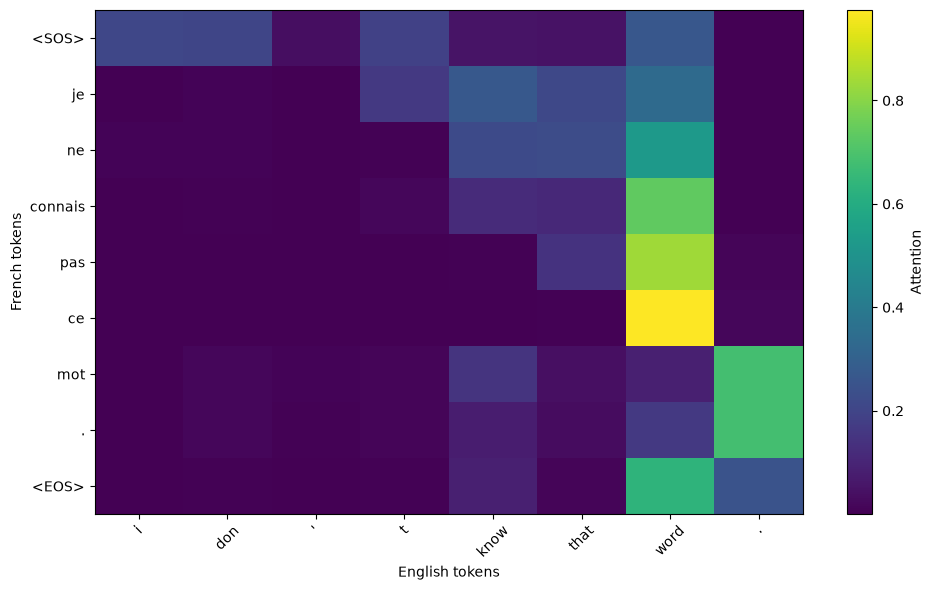

In [22]:
import matplotlib.pyplot as plt
model.eval()

with torch.no_grad():

    src, tgt, src_lengths, tgt_lengths = next(
        iter(train_dataloader)
    )

    src = src.to(device)
    tgt = tgt.to(device)
    src_lengths = src_lengths.cpu()

    example = 0

    tgt_input = tgt[:, :-1]

    logits, attentions = model(
        src,
        src_lengths,
        tgt_input
    )

    # -------------------------
    # Source tokens
    # -------------------------

    src_len = src_lengths[example].item()

    src_tokens = [
        eng_idx2word[idx.item()]
        for idx in src[example, :src_len]
    ]

    # -------------------------
    # Target tokens
    # -------------------------

    tgt_input_tokens = [
        fra_idx2word[idx.item()]
        for idx in tgt[example, :-1]
        if idx.item() != fra_word2idx["<PAD>"]
    ]

    # -------------------------
    # Attention
    # -------------------------

    attention = attentions[example].cpu()

    attention = attention[
        :len(tgt_input_tokens),
        :len(src_tokens)
    ]

    # -------------------------
    # Plot
    # -------------------------

    plt.figure(figsize=(10, 6))

    plt.imshow(
        attention,
        aspect="auto"
    )

    plt.xlabel("English tokens")
    plt.ylabel("French tokens")

    plt.xticks(
        range(len(src_tokens)),
        src_tokens,
        rotation=45
    )

    plt.yticks(
        range(len(tgt_input_tokens)),
        tgt_input_tokens
    )

    plt.colorbar(label="Attention")

    plt.tight_layout()
    plt.show()